# Mining the Asteroid Belt
### Discovering asteroid families with Data Mining & Warehousing

**Problem.** When two asteroids collide, the fragments end up on very similar orbits. These groups are called *asteroid families*.
Astronomers find them by clustering asteroids by their orbits. Can standard data-mining tools find them too?

**Source.** *Nesvorný HCM Asteroid Families V2.0*, NASA Planetary Data System (2024), doi:10.26033/5hyq-6k90. The bundle holds two things we use for different jobs:

| Role | File | What it is |
|---|---|---|
| **Primary dataset** (mined) | `proper_catalog24.tab` | 2024 catalogue of long-term orbits for 1,249,051 asteroids (Nesvorný et al. 2024) |
| **Reference labels** (never a clustering feature) | `families_2015/*.tab` | Official 2015 family memberships (Nesvorný et al. 2015), computed on an older orbit catalogue |

The 2015 labels are **never used as clustering features**: K-means and DBSCAN see only the orbits. They do influence the study in six places, each marked in the notebook: the Family dimension of the warehouse (OLAP), the family/unassigned item in the association rules, K-means' number of clusters k, the tuning of DBSCAN's `eps` and `min_samples` (on the outer belt only), the K-means diagnostic that removes unassigned asteroids first, and the evaluation. (The bundle's `families_2024/` folder lists only the 153 *new* families, so it can't serve as a complete answer key, and we don't use it.)

**Pipeline.** Extract → Transform → Load (star schema) → OLAP → Mining (K-means, DBSCAN, Apriori, outliers) → Evaluation

In [1]:
import glob, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import duckdb
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score
from mlxtend.frequent_patterns import apriori, association_rules
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 120)

DATA_DIR = "data/ast.nesvorny.families_V2_0/data"   # unzipped PDS bundle (see data/README.md)
FIG_DIR  = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# plot style: light surface, recessive grid, fixed categorical colours
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, INK, INK2 = "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "font.size": 12, "axes.axisbelow": True, "axes.titlesize": 14, "axes.titleweight": "bold", "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")

## 1. Extract
**Primary dataset:** the 2024 catalogue. Each row is one asteroid, described by its long-term (proper) orbit:
- `a`: semi-major axis, i.e. average distance from the Sun (AU)
- `e`: eccentricity, how oval the orbit is
- `sini`: sine of the inclination, how tilted the orbit is
- `H`: absolute magnitude (brightness). This is only a **size proxy**: true diameter also depends on how reflective the surface is, which this dataset doesn't contain.

In [2]:
cols = ["a", "a_err", "e", "e_err", "sini", "sini_err", "g", "s", "H", "n_opp", "packed", "name"]
catalog = pd.read_csv(f"{DATA_DIR}/proper_catalog24.tab", sep=r"\s+", header=None,
                      names=cols, dtype={"packed": str, "name": str})
print(f"Primary dataset (2024 catalogue): {len(catalog):,} asteroids x {catalog.shape[1]} columns")
catalog.head()

Primary dataset (2024 catalogue): 1,249,051 asteroids x 12 columns


,a,a_err,e,e_err,sini,sini_err,g,s,H,n_opp,packed,name
0,2.767028,2.300000e-05,0.115193,0.00016,0.167560,0.000013,54.253800,-59.249995,3.34,123,00001,1
1,2.771276,1.200000e-04,0.280234,0.00034,0.546016,0.000045,-1.372312,-46.451120,4.12,121,00002,2
2,2.669376,7.500000e-06,0.233600,0.00001,0.229144,0.000003,43.858531,-61.476025,5.17,114,00003,3
3,2.361512,5.900000e-08,0.099452,0.00014,0.111023,0.000180,36.882605,-39.610314,3.22,110,00004,4
4,2.577657,2.900000e-05,0.171249,0.01200,0.076113,0.001400,52.506470,-51.132322,7.00,87,00005,5


**Reference labels:** the 2015 family lists, one file per family. Some asteroids appear in two lists, because
small *sub-families* sit inside bigger ones (e.g. Karin inside Koronis). Rule: **an asteroid listed twice keeps the larger family's label**,
so each nested sub-family is absorbed into its parent.

In [3]:
rows = []
for f in sorted(glob.glob(f"{DATA_DIR}/families_2015/*.tab")):
    for line in open(f):
        p = line.split(None, 7)
        if p:
            rows.append((int(p[0]), int(p[6]), p[7].strip()))
members = pd.DataFrame(rows, columns=["number", "fam_id", "fam_name"])
fam_size = members.fam_id.value_counts()

overlap = members[members.number.duplicated(keep=False)]
print(f"Family files: {members.fam_id.nunique()}, label rows: {len(members):,}, unique asteroids: {members.number.nunique():,}")
print(f"Asteroids listed in two families: {members.number.duplicated().sum():,}")

# keep-larger rule: sort by family size (largest first), then keep the first label per asteroid
labels = (members.assign(size=members.fam_id.map(fam_size))
                 .sort_values(["size", "fam_id"], ascending=[False, True])
                 .drop_duplicates("number").drop(columns="size"))
absorbed = sorted(set(members.fam_name) - set(labels.fam_name))
print(f"Sub-families fully absorbed into a parent ({len(absorbed)}): {', '.join(absorbed)}")

Family files: 119, label rows: 143,711, unique asteroids: 139,961
Asteroids listed in two families: 3,750
Sub-families fully absorbed into a parent (10): 1270 Datura, 144 Vibilia, 14627 Emilkowalski, 158 Koronis(2), 21509 Lucascavin, 2384 Schulhof, 298 Baptistina, 618 Elfriede, 656 Beagle, 832 Karin


## 2. Transform: cleaning, integration & feature engineering
Every step is logged, so the row counts can go straight onto the ETL slide.

In [4]:
log = [("Raw 2024 catalogue", len(catalog))]

# numbered asteroids only: the 2015 labels identify asteroids by number
df = catalog.assign(number=pd.to_numeric(catalog["name"], errors="coerce"))
df = df[df.number.notna()]
log.append(("Numbered asteroids only", len(df)))

# same population the 2015 labels were built on: numbered up to the highest labelled number
MAX_LABELLED = labels.number.max()
df = df[df.number <= MAX_LABELLED]
log.append((f"Number <= {MAX_LABELLED:,} (2015 label population)", len(df)))

# main belt only (2.0 - 3.3 AU); Hungarias, Hildas and Trojans are separate populations
df = df[(df.a > 2.0) & (df.a < 3.3)]
log.append(("Main belt, 2.0 < a < 3.3 AU", len(df)))

# sentinel values: H = 99.99 means 'unknown' (none survive the previous filters, kept as a safety check)
df = df[df.H < 30]
log.append(("Valid absolute magnitude H", len(df)))

etl_log = pd.DataFrame(log, columns=["step", "rows"])
etl_log["removed"] = (-etl_log.rows.diff()).fillna(0).astype(int)
etl_log

,step,rows,removed
0,Raw 2024 catalogue,1249051,0
1,Numbered asteroids only,622886,626165
2,"Number <= 399,153 (2015 label population)",389667,233219
3,"Main belt, 2.0 < a < 3.3 AU",382730,6937
4,Valid absolute magnitude H,382730,0


**Integration: LEFT JOIN.** The catalogue is the left table and the 2015 labels are the right table.
Every catalogue asteroid is kept. An asteroid with no matching label is **unassigned** (`fam_id = -1`), not deleted. Unassigned means "not in any 2015 reference family", not proven to be unrelated.
Labels with no matching catalogue row are dropped, and we count them below.

In [5]:
df["number"] = df.number.astype(int)
df = df.merge(labels, on="number", how="left")                # LEFT JOIN
df["fam_id"] = df.fam_id.fillna(-1).astype(int)              # -1 = unassigned (no 2015 family label)
df["fam_name"] = df.fam_name.fillna("Unassigned")

in_catalog = labels.number.isin(pd.to_numeric(catalog["name"], errors="coerce"))
in_final = labels.number.isin(df.number)
join_report = pd.DataFrame([
    ("Unique labelled asteroids (after overlap rule)", len(labels)),
    ("  not found in the 2024 catalogue (mostly Hilda & Trojan families, outside the main belt)", int((~in_catalog).sum())),
    ("  found, but removed by our filters", int((in_catalog & ~in_final).sum())),
    ("    of which the Hungaria family (a < 2.0 AU)", int((in_catalog & ~in_final & (labels.fam_name == "434 Hungaria")).sum())),
    ("  matched into the final dataset", int(in_final.sum())),
    ("Final dataset: labelled family members", int((df.fam_id >= 0).sum())),
    ("Final dataset: unassigned (no label)", int((df.fam_id < 0).sum())),
    ("Families present in the final dataset", int(df.loc[df.fam_id >= 0, "fam_id"].nunique())),
], columns=["item", "count"])
join_report

,item,count
0,Unique labelled asteroids (after overlap rule),139961
1,"not found in the 2024 catalogue (mostly Hilda & Trojan families, outside the main belt)",1132
2,"found, but removed by our filters",3246
3,of which the Hungaria family (a < 2.0 AU),2965
4,matched into the final dataset,135583
5,Final dataset: labelled family members,135583
6,Final dataset: unassigned (no label),247147
7,Families present in the final dataset,98


**Family count, reconciled.** 119 family lists → 109 families after merging the nested sub-families → the families that still have members in our data.

In [6]:
n_lists = members.fam_id.nunique()
n_merged = labels.fam_id.nunique()
n_final = df.loc[df.fam_id >= 0, "fam_id"].nunique()
lost = labels[~labels.fam_id.isin(df.fam_id)].drop_duplicates("fam_id").sort_values("fam_id")
print(f"{n_lists} lists -> {n_merged} after merging {n_lists - n_merged} sub-families -> {n_final} with members in our data")
in_cat = lost.fam_id.isin(labels[in_catalog].fam_id)
print("Not in the 2024 main-belt catalogue:", ", ".join(lost.loc[~in_cat, "fam_name"]))
print("Outside our 2.0-3.3 AU window      :", ", ".join(lost.loc[in_cat, "fam_name"]))

119 lists -> 109 after merging 10 sub-families -> 98 with members in our data
Not in the 2024 main-belt catalogue: 153 Hilda, 1911 Schubart, 624 Hector, 3548 Eurybates, 9799 1996 RJ, 20961 Arkesilaos, 4709 Ennomos, 247341 2001 UV209
Outside our 2.0-3.3 AU window      : 434 Hungaria, 87 Sylvia, 909 Ulla


**Feature engineering:** derived attributes that become warehouse dimensions.

In [7]:
df["incl_deg"] = np.degrees(np.arcsin(df.sini))
df["zone"] = pd.cut(df.a, [2.0, 2.5, 2.82, 3.3], labels=["inner", "middle", "outer"]).astype(str)
df["a_bin"] = (np.floor((df.a - 2.0) / 0.02) * 0.02 + 2.0).round(2)      # 0.02 AU bins; zone edges fall on bin edges
# pd.cut intervals are right-closed: low = (0, 5] deg, moderate = (5, 15], high = (15, 90]; same for H below
df["incl_class"] = pd.cut(df.incl_deg, [0, 5, 15, 90], labels=["low", "moderate", "high"]).astype(str)
df["size_class"] = pd.cut(df.H, [0, 13, 16, 30], labels=["large", "medium", "small"]).astype(str)   # brightness-based size proxy
assert df.groupby("a_bin").zone.nunique().max() == 1      # every distance bin sits inside exactly one zone
print(f"Final: {len(df):,} asteroids | {(df.fam_id >= 0).mean():.1%} family members | "
      f"{df.loc[df.fam_id >= 0, 'fam_id'].nunique()} families | {df.a_bin.nunique()} distance bins")

Final: 382,730 asteroids | 35.4% family members | 98 families | 65 distance bins


## 3. Load: star schema (DuckDB)

```
                 dim_location (a_bin -> zone -> belt)
                          |
 dim_family ---- fact_asteroid ---- dim_inclination
                          |
                      dim_size
```

**Fact table `fact_asteroid`** (grain: one row per asteroid)
- `asteroid_id`: degenerate dimension (the asteroid number; it has no dimension table of its own)
- foreign keys to the four dimensions
- `asteroid_count = 1`: the only **additive measure**. Summing it over any dimension gives a valid count.
- `a, e, sin_i, H`: **numeric attributes, not additive**. Adding two orbits' distances means nothing, so we use AVG / MIN / MAX on them, never SUM. H is a logarithmic brightness and only a size proxy.

**Dimension hierarchies**
- Location: `a_bin` (0.02 AU) → `zone` (inner / middle / outer) → `belt` (all)
- Family: `family_name` → `membership` (family / unassigned) → all. Built from the 2015 reference labels: used for OLAP, never for clustering.
- Inclination and Size: single level (`incl_class`, `size_class`)

In [8]:
con = duckdb.connect()   # in-memory warehouse
con.register("staging", df)

con.execute(r'''
CREATE TABLE dim_location AS
  SELECT ROW_NUMBER() OVER (ORDER BY a_bin) AS location_key,
         a_bin AS a_bin_start, a_bin + 0.02 AS a_bin_end, zone, 'main belt' AS belt
  FROM (SELECT DISTINCT a_bin, zone FROM staging);
CREATE TABLE dim_inclination AS
  SELECT * FROM (VALUES (1,'low',0,5), (2,'moderate',5,15), (3,'high',15,90))
  AS t(incl_key, incl_class, deg_min, deg_max);
CREATE TABLE dim_size AS
  SELECT * FROM (VALUES (1,'large','H <= 13'), (2,'medium','13 < H <= 16'), (3,'small','H > 16'))
  AS t(size_key, size_class, h_range);
CREATE TABLE dim_family AS
  SELECT DISTINCT fam_id AS family_key, fam_name AS family_name,
         CASE WHEN fam_id >= 0 THEN 'family' ELSE 'unassigned' END AS membership
  FROM staging;
''')

con.execute(r'''
CREATE TABLE fact_asteroid AS
SELECT s.number      AS asteroid_id,         -- degenerate dimension
       l.location_key, i.incl_key, z.size_key, s.fam_id AS family_key,
       1             AS asteroid_count,      -- additive measure
       s.a, s.e, s.sini AS sin_i, s.H        -- numeric attributes (AVG/MIN/MAX only)
FROM staging s
JOIN dim_location l     ON s.a_bin = l.a_bin_start
JOIN dim_inclination i  ON s.incl_class = i.incl_class
JOIN dim_size z         ON s.size_class = z.size_class;
''')

for t in ["fact_asteroid", "dim_location", "dim_inclination", "dim_size", "dim_family"]:
    print(f"{t:16s} {con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]:>8,} rows")
assert con.execute("SELECT SUM(asteroid_count) FROM fact_asteroid").fetchone()[0] == len(df)   # no rows lost in the joins

fact_asteroid     382,730 rows
dim_location           65 rows
dim_inclination         3 rows
dim_size                3 rows
dim_family             99 rows


## 4. OLAP operations
**Roll-up** along the Location hierarchy: distance bin → zone → whole belt. `GROUP BY ROLLUP` returns every level in one query;
below we show the zone subtotals and the grand total.

In [9]:
rollup = con.execute(r'''
SELECT COALESCE(l.zone, 'ALL')                    AS zone,
       COALESCE(CAST(l.a_bin_start AS VARCHAR), 'ALL') AS a_bin,
       CAST(SUM(f.asteroid_count) AS BIGINT)                       AS n_asteroids,
       ROUND(AVG(f.e), 3)                          AS avg_e
FROM fact_asteroid f JOIN dim_location l USING (location_key)
GROUP BY ROLLUP (l.zone, l.a_bin_start)
ORDER BY l.zone NULLS LAST, l.a_bin_start NULLS FIRST
''').df()
print(f"{len(rollup)} rows in total (bins + zone subtotals + grand total)")
rollup[rollup.a_bin == "ALL"]

69 rows in total (bins + zone subtotals + grand total)


,zone,a_bin,n_asteroids,avg_e
0,inner,ALL,134714,0.148
26,middle,ALL,139010,0.138
43,outer,ALL,109006,0.117
68,ALL,ALL,382730,0.135


**Drill-down**: from the outer zone down to its 0.02 AU distance bins. The dip around 2.96 AU is the 7:3 Kirkwood gap.

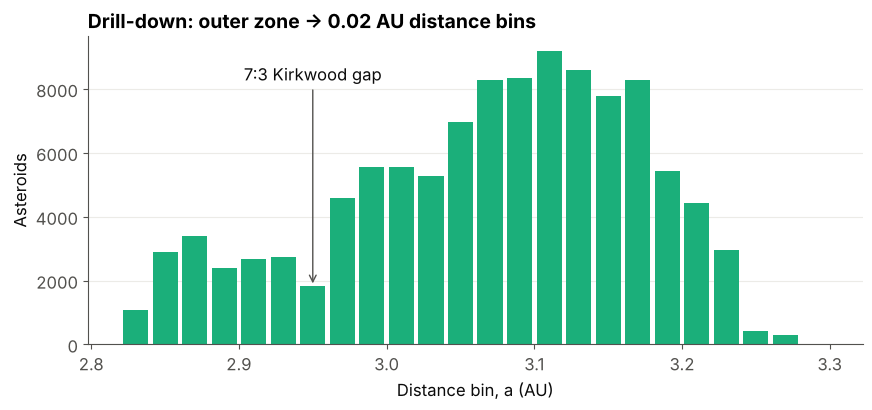

,a_bin,n_asteroids
0,2.82,1069
1,2.84,2903
2,2.86,3411
3,2.88,2381
4,2.90,2689
5,2.92,2739
6,2.94,1824
7,2.96,4590


In [10]:
drill = con.execute(r'''
SELECT l.a_bin_start AS a_bin, CAST(SUM(f.asteroid_count) AS BIGINT) AS n_asteroids
FROM fact_asteroid f JOIN dim_location l USING (location_key)
WHERE l.zone = 'outer'
GROUP BY l.a_bin_start ORDER BY l.a_bin_start
''').df()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(drill.a_bin + 0.01, drill.n_asteroids, width=0.017, color=AQUA)
ax.annotate("7:3 Kirkwood gap", xy=(2.95, drill.set_index("a_bin").n_asteroids.get(2.94, 0)), xytext=(2.95, drill.n_asteroids.max() * 0.9),
            ha="center", color=INK, arrowprops=dict(arrowstyle="->", color=INK2))
ax.set_xlabel("Distance bin, a (AU)"); ax.set_ylabel("Asteroids"); ax.grid(axis="x", visible=False)
ax.set_title("Drill-down: outer zone -> 0.02 AU distance bins", loc="left")
save(fig, "olap_drilldown"); plt.show()
drill.head(8)

**Slice**: fix one dimension (inclination = high) and look at the remaining sub-cube.

In [11]:
slice_q = con.execute(r'''
SELECT l.zone, CAST(SUM(f.asteroid_count) AS BIGINT) AS n_asteroids,
       ROUND(100.0 * SUM(CASE WHEN d.membership = 'family' THEN f.asteroid_count ELSE 0 END)
             / SUM(f.asteroid_count), 1) AS pct_in_families
FROM fact_asteroid f
JOIN dim_location l USING (location_key) JOIN dim_inclination i USING (incl_key) JOIN dim_family d USING (family_key)
WHERE i.incl_class = 'high'
GROUP BY l.zone ORDER BY l.zone
''').df()
slice_q

,zone,n_asteroids,pct_in_families
0,inner,3603,57.5
1,middle,9647,36.4
2,outer,18192,39.5


**Dice**: select a sub-cube on two dimensions at once: zone ∈ {middle, outer} **and** size ∈ {large, medium}.

In [12]:
dice_q = con.execute(r'''
SELECT l.zone, z.size_class, CAST(SUM(f.asteroid_count) AS BIGINT) AS n_asteroids, ROUND(AVG(f.H), 2) AS avg_H
FROM fact_asteroid f JOIN dim_location l USING (location_key) JOIN dim_size z USING (size_key)
WHERE l.zone IN ('middle', 'outer') AND z.size_class IN ('large', 'medium')
GROUP BY l.zone, z.size_class ORDER BY l.zone, z.size_class
''').df()
dice_q

,zone,size_class,n_asteroids,avg_H
0,middle,large,1589,11.74
1,middle,medium,55785,15.20
2,outer,large,3262,11.90
3,outer,medium,75269,15.10


**Pivot (rotate)**: turn the size dimension from rows into columns: zone × size, showing the % of asteroids in families.

In [13]:
pivot = con.execute(r'''
PIVOT (
  SELECT l.zone, z.size_class,
         CASE WHEN d.membership = 'family' THEN 100.0 ELSE 0 END AS pct_family
  FROM fact_asteroid f
  JOIN dim_location l USING (location_key) JOIN dim_size z USING (size_key) JOIN dim_family d USING (family_key)
) ON size_class USING ROUND(AVG(pct_family), 1) GROUP BY zone ORDER BY zone
''').df()[["zone", "large", "medium", "small"]]
pivot

,zone,large,medium,small
0,inner,35.5,44.6,44.6
1,middle,34.8,29.9,23.8
2,outer,48.3,36.3,32.9


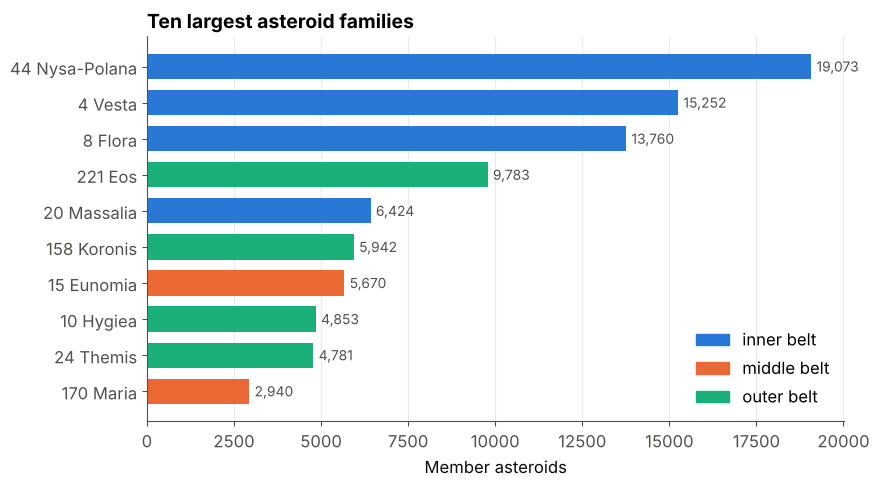

In [14]:
# aggregation over the Family dimension: the ten largest families, coloured by the zone holding most of their members
top = con.execute(r'''
SELECT d.family_name, l.zone, CAST(SUM(f.asteroid_count) AS BIGINT) AS n
FROM fact_asteroid f JOIN dim_location l USING (location_key) JOIN dim_family d USING (family_key)
WHERE d.membership = 'family' GROUP BY d.family_name, l.zone
QUALIFY ROW_NUMBER() OVER (PARTITION BY d.family_name ORDER BY n DESC) = 1
ORDER BY n DESC LIMIT 10
''').df().iloc[::-1]
zc = {"inner": BLUE, "middle": ORANGE, "outer": AQUA}
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.family_name, top.n, color=[zc[z] for z in top.zone], height=0.7)
for yy, n in enumerate(top.n):
    ax.text(n + 150, yy, f"{n:,}", va="center", color=INK2, fontsize=10)
ax.set_xlabel("Member asteroids"); ax.grid(axis="y", visible=False)
ax.set_title("Ten largest asteroid families", loc="left")
ax.legend(handles=[Patch(color=c, label=f"{z} belt") for z, c in zc.items()], loc="lower right")
save(fig, "olap_top_families"); plt.show()

## 5. Exploring the data
The distribution of semi-major axis shows the **Kirkwood gaps**: empty bands where an asteroid's orbital period
would be a simple fraction of Jupiter's (resonances), so Jupiter's gravity clears them out.

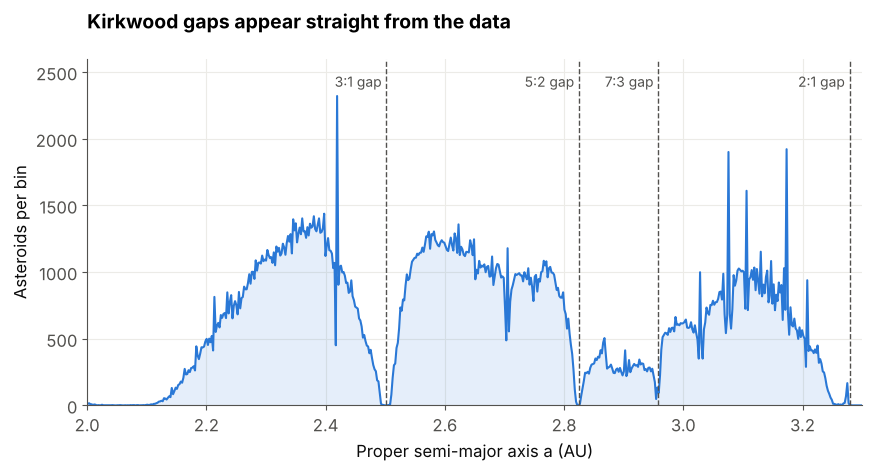

In [15]:
gaps = {"3:1": 2.502, "5:2": 2.825, "7:3": 2.958, "2:1": 3.279}
fig, ax = plt.subplots(figsize=(10, 4.5))
counts, edges = np.histogram(df.a, bins=600, range=(2.0, 3.3))
ax.plot((edges[:-1] + edges[1:]) / 2, counts, color=BLUE, lw=1.5)
ax.fill_between((edges[:-1] + edges[1:]) / 2, counts, color=BLUE, alpha=0.12, lw=0)
for lab, x in gaps.items():
    ax.axvline(x, color=INK2, lw=1, ls="--")
    ax.text(x - 0.008, counts.max() * 1.03, f"{lab} gap", ha="right", color=INK2, fontsize=10)
ax.set_xlabel("Proper semi-major axis a (AU)"); ax.set_ylabel("Asteroids per bin")
ax.set_title("Kirkwood gaps appear straight from the data", loc="left", pad=22)
ax.set_xlim(2.0, 3.3); ax.set_ylim(0, counts.max() * 1.12)
save(fig, "eda_kirkwood"); plt.show()

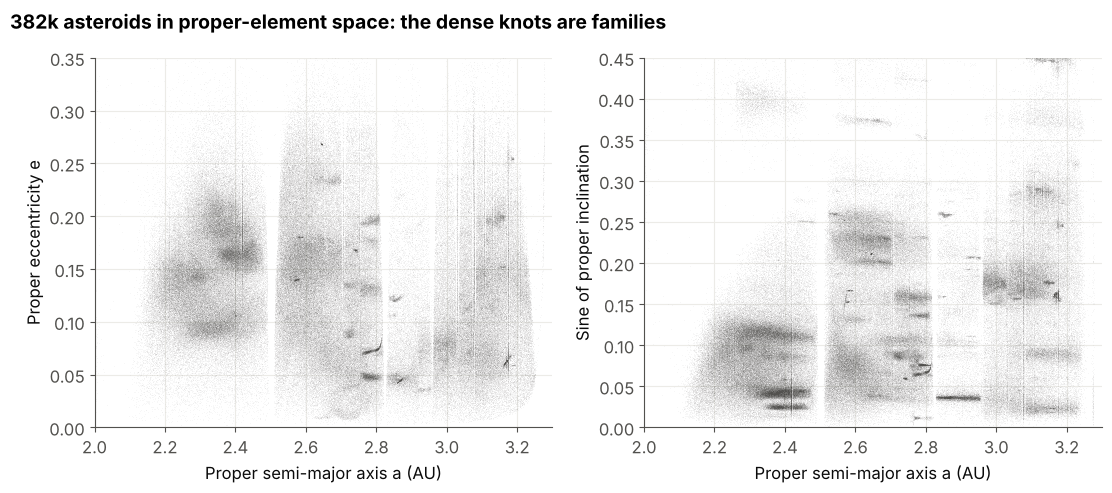

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, lab in [(axes[0], "e", "Proper eccentricity e"), (axes[1], "sini", "Sine of proper inclination")]:
    ax.scatter(df.a, df[col], s=0.05, color=INK2, alpha=0.25, rasterized=True, linewidths=0)
    ax.set_xlabel("Proper semi-major axis a (AU)"); ax.set_ylabel(lab); ax.set_xlim(2.0, 3.3)
axes[1].set_ylim(0, 0.45); axes[0].set_ylim(0, 0.35)
fig.suptitle("382k asteroids in proper-element space: the dense knots are families", x=0.06, ha="left",
             fontweight="bold", fontsize=14)
save(fig, "eda_scatter"); plt.show()

## 6. Feature scaling: a physically meaningful distance
Astronomers measure how far apart two orbits are as the **velocity kick** needed to move from one to the other (Zappalà et al. 1990):

$$d = na\sqrt{\tfrac54\left(\tfrac{\delta a}{a}\right)^2 + 2(\delta e)^2 + 2(\delta \sin i)^2}\quad[\text{m/s}]$$

Scaling the features this way makes plain Euclidean distance equal to $d$ in m/s, so `eps` in DBSCAN becomes a velocity cutoff.
Clustering is run **separately per zone**, as in the original family search.

In [17]:
def hcm_features(z):
    v = 29780 / np.sqrt(z.a.median())            # orbital speed n*a (m/s) at the zone centre
    return np.c_[np.sqrt(1.25) * np.log(z.a), np.sqrt(2) * z.e, np.sqrt(2) * z.sini] * v

ZONES = ["inner", "middle", "outer"]
X = {zn: hcm_features(df[df.zone == zn]) for zn in ZONES}
y = {zn: df.loc[df.zone == zn, "fam_id"].values for zn in ZONES}
for zn in ZONES:
    print(f"{zn:7s} {len(y[zn]):>7,} asteroids, {len(set(y[zn])) - 1:>3} true families")

inner   134,714 asteroids,  16 true families
middle  139,010 asteroids,  44 true families
outer   109,006 asteroids,  41 true families


**Checking the distance claim.** We did **not** use StandardScaler. The scaling above is specific to this problem, so Euclidean distance should be
close to the exact formula. Test: take each asteroid's 20 nearest neighbours and compare our distance with the exact $d$, computed with
$na$ at the pair's own mean distance from the Sun.

In [18]:
check = []
for zn in ZONES:
    z = df[df.zone == zn]; A, E, S = z.a.values, z.e.values, z.sini.values
    dist, idx = NearestNeighbors(n_neighbors=21).fit(X[zn]).kneighbors(X[zn][:20000])
    i = np.repeat(np.arange(20000), 20); j = idx[:, 1:].ravel(); ours = dist[:, 1:].ravel()
    am = (A[i] + A[j]) / 2
    exact = 29780 / np.sqrt(am) * np.sqrt(1.25 * ((A[i] - A[j]) / am) ** 2 + 2 * (E[i] - E[j]) ** 2 + 2 * (S[i] - S[j]) ** 2)
    r = ours / exact
    check.append((zn, len(r), np.median(r), np.percentile(r, 1), np.percentile(r, 99)))
pd.DataFrame(check, columns=["zone", "pairs", "median ratio", "1st pct", "99th pct"]).round(3)

,zone,pairs,median ratio,1st pct,99th pct
0,inner,400000,0.997,0.959,1.028
1,middle,400000,0.998,0.975,1.029
2,outer,400000,0.998,0.960,1.024


Our Euclidean distance matches the exact formula to within a few percent (median ratio ≈ 1.00), so `eps` can fairly be read as **≈ 80 m/s**.
The small error comes from using one reference speed per zone, and from $\delta \ln a$ standing in for $\delta a / a$.

## 7. First attempt: K-means
K-means is given the true number of families per zone (taken from the reference labels). Its main problem here: it must put **every** asteroid in a cluster,
but about 65% of asteroids have no assignment in the 2015 reference catalogue. K-means has no way to say "this point is noise".

In [19]:
km_labels = {}
for zn in ZONES:
    k = len(set(y[zn])) - 1
    km_labels[zn] = KMeans(n_clusters=k, n_init=5, random_state=0).fit_predict(X[zn])
    print(f"{zn:7s} k={k:>3}  ARI = {adjusted_rand_score(y[zn], km_labels[zn]):.3f}")

inner   k= 16  ARI = 0.074


middle  k= 44  ARI = 0.010


outer   k= 41  ARI = 0.029


## 8. DBSCAN: density-based clustering
DBSCAN fits this problem: families are **dense** regions, asteroids outside any dense group become **noise** (label −1), and clusters can take any shape. Noise means *unassigned at this density*, not confirmed background.
It is closely related to the astronomers' Hierarchical Clustering Method, which is single-linkage clustering with a velocity cutoff.

**Choosing `eps`:** the k-distance plot (k = `min_samples` = 20) shows, for each asteroid, the distance to its 20th-nearest point *counting the asteroid itself*. That is the same rule DBSCAN uses: a core point has at least 20 points, itself included, within `eps`.

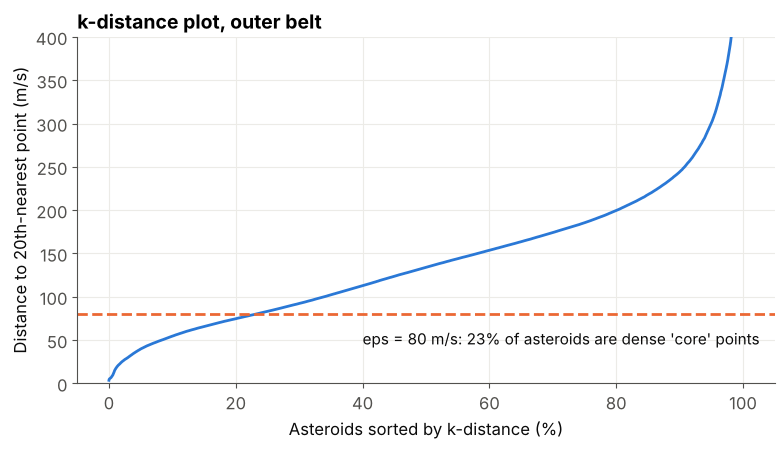

In [20]:
MIN_SAMPLES, EPS = 20, 80        # 80 m/s velocity cutoff
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X["outer"])
kdist = np.sort(nn.kneighbors(X["outer"])[0][:, -1])
frac_core = (kdist <= EPS).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.linspace(0, 100, len(kdist)), kdist, color=BLUE, lw=2)
ax.axhline(EPS, color=ORANGE, lw=2, ls="--")
ax.text(40, EPS - 35, f"eps = {EPS} m/s: {frac_core:.0%} of asteroids are dense 'core' points", color=INK, fontsize=11)
ax.set_ylim(0, 400); ax.set_xlabel("Asteroids sorted by k-distance (%)"); ax.set_ylabel("Distance to 20th-nearest point (m/s)")
ax.set_title("k-distance plot, outer belt", loc="left")
save(fig, "dbscan_kdist"); plt.show()

**Tuning (validation):** `eps` and `min_samples` were chosen on the **outer belt** by checking ARI against the 2015 labels.
The chosen setting (80 m/s, 20) is then applied **unchanged** to the inner and middle belts as **transfer tests**: no retuning there.

In [21]:
grid = []
for eps in [50, 60, 70, 80, 90]:
    for ms in [10, 20, 40]:
        lab = DBSCAN(eps=eps, min_samples=ms, n_jobs=-1).fit_predict(X["outer"])
        grid.append((eps, ms, round(adjusted_rand_score(y["outer"], lab), 3)))
pd.DataFrame(grid, columns=["eps", "min_samples", "ARI"]).pivot(index="eps", columns="min_samples", values="ARI")

min_samples,10,20,40
eps,,,
50,0.535,0.327,0.183
60,0.647,0.461,0.277
70,0.615,0.610,0.378
80,0.552,0.650,0.490
90,0.458,0.618,0.603


In [22]:
db_labels = {zn: DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(X[zn]) for zn in ZONES}
for zn in ZONES:
    lab = db_labels[zn]
    print(f"{zn:7s} clusters found = {lab.max() + 1:>3}, noise = {(lab == -1).mean():.0%}, "
          f"ARI = {adjusted_rand_score(y[zn], lab):.3f}")

inner   clusters found =  70, noise = 63%, ARI = 0.643
middle  clusters found = 110, noise = 73%, ARI = 0.607
outer   clusters found =  66, noise = 69%, ARI = 0.650


## 9. Evaluation against the 2015 reference labels
- **ARI** (Adjusted Rand Index): agreement between our clustering and the reference labels (1 = perfect, 0 = random).
  **How noise is handled:** in the main score, all unassigned reference asteroids form one class (`-1`) and all DBSCAN noise forms one predicted class (`-1`),
  so ARI rewards separating family members from unassigned asteroids *and* telling families apart. Other ways of scoring it are shown further down.
- **Precision**: of the asteroids we put in a family, the fraction that really are family members.
- **Recall**: of the reference family members, the fraction that we put in some cluster.

In [23]:
def scores(truth, lab):
    fp, ft = lab >= 0, truth >= 0
    return adjusted_rand_score(truth, lab), (fp & ft).sum() / max(fp.sum(), 1), (fp & ft).sum() / ft.sum()

res = []
for zn in ZONES:
    for method, lab in [("K-means", km_labels[zn]), ("DBSCAN", db_labels[zn])]:
        ari, p, r = scores(y[zn], lab)
        if method == "K-means":      # K-means has no noise label, so every asteroid is 'in a family'
            p, r = (y[zn] >= 0).mean(), 1.0
        res.append((zn, method, ari, p, r))
evaluation = pd.DataFrame(res, columns=["zone", "method", "ARI", "precision", "recall"]).round(3)
evaluation

,zone,method,ARI,precision,recall
0,inner,K-means,0.074,0.445,1.000
1,inner,DBSCAN,0.643,0.928,0.765
2,middle,K-means,0.010,0.264,1.000
3,middle,DBSCAN,0.607,0.729,0.753
4,outer,K-means,0.029,0.357,1.000
5,outer,DBSCAN,0.650,0.862,0.756


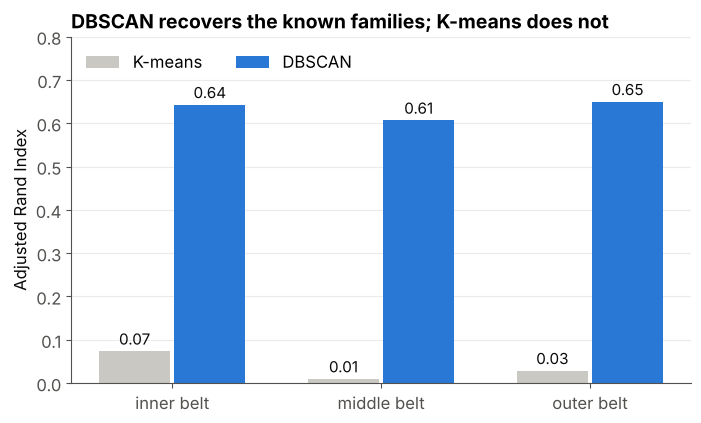

In [24]:
fig, ax = plt.subplots(figsize=(8, 4.5))
xpos = np.arange(len(ZONES)); w = 0.36
for j, (method, c) in enumerate([("K-means", GREY), ("DBSCAN", BLUE)]):
    vals = evaluation[evaluation.method == method].set_index("zone").loc[ZONES, "ARI"].values
    bars = ax.bar(xpos + (j - 0.5) * w, vals, w * 0.94, color=c, label=method)
    for xb, v in zip(xpos + (j - 0.5) * w, vals):
        ax.text(xb, v + 0.015, f"{v:.2f}", ha="center", color=INK, fontsize=11)
ax.set_xticks(xpos, [f"{z} belt" for z in ZONES]); ax.set_ylim(0, 0.8); ax.set_ylabel("Adjusted Rand Index")
ax.grid(axis="x", visible=False); ax.legend(loc="upper left", ncol=2)
ax.set_title("DBSCAN recovers the known families; K-means does not", loc="left")
save(fig, "eval_ari"); plt.show()

**Why exactly does K-means fail?** Test: remove the unassigned asteroids first (which we could only do because we have the reference labels)
and run K-means on the true family members alone. It then separates the families reasonably well.
So K-means' real weakness here is that it has no concept of noise; DBSCAN's advantage is that it can leave asteroids unassigned.

In [25]:
for zn in ZONES:
    mm = y[zn] >= 0
    k = len(set(y[zn])) - 1
    lab = KMeans(n_clusters=k, n_init=5, random_state=0).fit_predict(X[zn][mm])
    print(f"{zn:7s} K-means on family members only: ARI = {adjusted_rand_score(y[zn][mm], lab):.2f}")

inner   K-means on family members only: ARI = 0.46


middle  K-means on family members only: ARI = 0.66


outer   K-means on family members only: ARI = 0.39


**Robustness: other ways of scoring noise.** The conclusion shouldn't depend on one scoring choice:
- *noise as singletons*: every unassigned / noise asteroid counts as its own one-point cluster
- *members & clustered only*: only asteroids that are reference members **and** DBSCAN placed in a cluster. This asks "when DBSCAN does assign a family, is it the right one?"

In [26]:
var = []
for zn in ZONES:
    t, p = y[zn], db_labels[zn]
    t_s = np.where(t < 0, -(np.arange(len(t)) + 2), t)       # unique id per unassigned point
    p_s = np.where(p < 0, -(np.arange(len(p)) + 2), p)       # unique id per noise point
    both = (t >= 0) & (p >= 0)
    var.append((zn, adjusted_rand_score(t, p), adjusted_rand_score(t_s, p_s), adjusted_rand_score(t[both], p[both])))
pd.DataFrame(var, columns=["zone", "ARI (unassigned = 1 class)", "ARI (noise as singletons)", "ARI (members & clustered)"]).round(2)

,zone,ARI (unassigned = 1 class),ARI (noise as singletons),ARI (members & clustered)
0,inner,0.64,0.65,0.74
1,middle,0.61,0.54,0.86
2,outer,0.65,0.68,0.90


**Per-family recovery: exact procedure**
1. Take every reference family with at least **2,000 members** in our data.
2. For each, find the DBSCAN cluster containing the most of its members (noise excluded).
3. Score the match with **Jaccard = |family ∩ cluster| / |family ∪ cluster|**, which penalises both missed members and extra asteroids.
4. Count the family as **recovered if Jaccard > 0.5**. The threshold sensitivity and one-to-one matching are checked below.

In [27]:
rows = []
for zn in ZONES:
    sub = df[df.zone == zn].assign(pred=db_labels[zn])
    for fid, g in sub[sub.fam_id >= 0].groupby("fam_id"):
        if len(g) < 2000: continue
        best = g.pred[g.pred >= 0].value_counts()
        c, inter = best.index[0], best.iloc[0]
        csize = (sub.pred == c).sum()
        rows.append((g.fam_name.iloc[0], zn, len(g), c, inter / len(g), inter / csize, inter / (len(g) + csize - inter)))
recovery = (pd.DataFrame(rows, columns=["family", "zone", "members", "best_cluster", "recall", "precision", "jaccard"])
              .sort_values("members", ascending=False).reset_index(drop=True))
recovery["recovered"] = recovery.jaccard > 0.5
recovery.round(2)

,family,zone,members,best_cluster,recall,precision,jaccard,recovered
0,44 Nysa-Polana,inner,19073,1,0.92,0.71,0.67,True
1,4 Vesta,inner,15252,0,0.92,0.96,0.88,True
2,8 Flora,inner,13760,3,0.32,0.90,0.31,False
3,221 Eos,outer,9783,6,0.97,0.71,0.70,True
4,20 Massalia,inner,6424,1,0.96,0.25,0.25,False
5,158 Koronis,outer,5942,4,0.99,0.92,0.91,True
6,15 Eunomia,middle,5670,2,0.83,0.94,0.79,True
7,10 Hygiea,outer,4853,0,0.63,0.98,0.62,True
8,24 Themis,outer,4781,1,0.67,0.98,0.66,True
9,170 Maria,middle,2940,12,0.20,0.98,0.20,False


In [28]:
for t in (0.4, 0.5, 0.6):
    print(f"Recovered at Jaccard > {t}: {(recovery.jaccard > t).sum()} of {len(recovery)}")
shared = recovery.groupby(["zone", "best_cluster"]).family.apply(list).loc[lambda s: s.str.len() > 1]
for (zn, c), fams in shared.items():
    print(f"Cluster {c} ({zn}) is the best match for {fams}: under one-to-one matching only the higher-Jaccard family keeps it")
one_to_one = recovery.sort_values("jaccard", ascending=False).drop_duplicates(["zone", "best_cluster"])
print(f"Recovered with one-to-one matching: {(one_to_one.jaccard > 0.5).sum()} of {len(recovery)}")

Recovered at Jaccard > 0.4: 10 of 14
Recovered at Jaccard > 0.5: 10 of 14
Recovered at Jaccard > 0.6: 9 of 14
Cluster 1 (inner) is the best match for ['44 Nysa-Polana', '20 Massalia']: under one-to-one matching only the higher-Jaccard family keeps it
Recovered with one-to-one matching: 10 of 14


**Reading the misses.** Ten of the 14 large families are recovered, and the result holds for any threshold from 0.4 to 0.5 and under one-to-one matching. The four misses fail in two different ways:
- **Low recall** (Flora, Maria, Euphrosyne): the family is spread out, so at 80 m/s most of its members fall below DBSCAN's density threshold and become noise. The cluster DBSCAN does find is pure (precision ≈ 0.9+) but small.
- **Low precision** (Massalia): it sits next to Nysa-Polana and the two get chained into one cluster.

This is the trade-off of a single global `eps`: one density threshold can't suit every family.

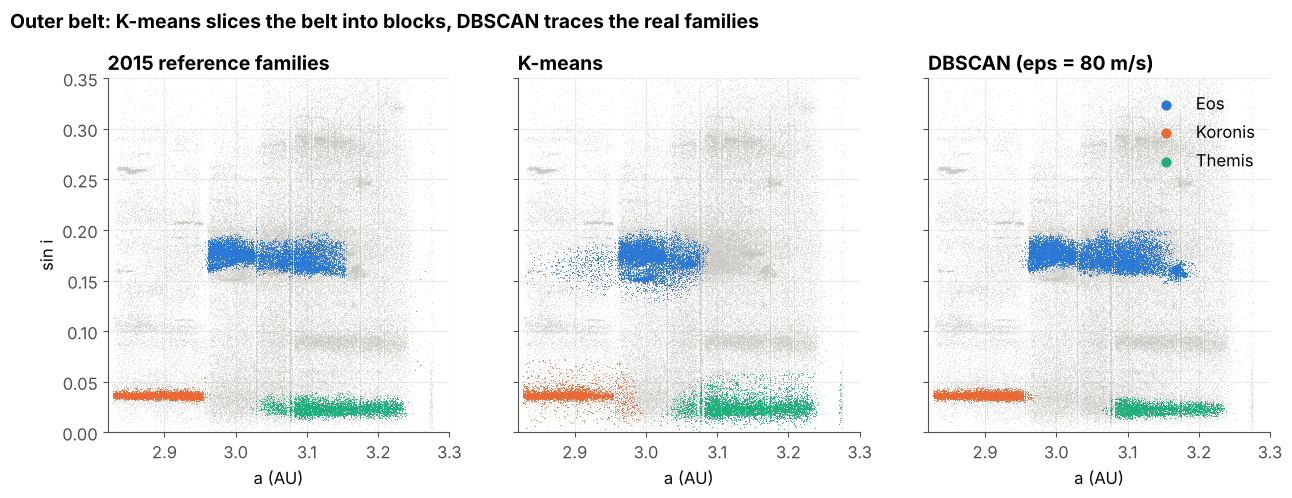

In [29]:
# side-by-side view of the outer belt: truth vs K-means vs DBSCAN (3 big families highlighted)
fams = [("221 Eos", BLUE), ("158 Koronis", ORANGE), ("24 Themis", AQUA)]
sub = df[df.zone == "outer"].reset_index(drop=True)
views = {"2015 reference families": sub.fam_id.values, "K-means": km_labels["outer"], "DBSCAN (eps = 80 m/s)": db_labels["outer"]}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (title, lab) in zip(axes, views.items()):
    ax.scatter(sub.a, sub.sini, s=0.15, color=GREY, rasterized=True, linewidths=0)
    for name, c in fams:
        is_true = (sub.fam_name == name).values
        if title == "2015 reference families":
            mask = is_true
        else:
            vc = pd.Series(lab[is_true & (lab >= 0)]).value_counts()
            mask = lab == vc.index[0]
        ax.scatter(sub.a[mask], sub.sini[mask], s=0.4, color=c, rasterized=True, linewidths=0)
    ax.set_title(title, loc="left"); ax.set_xlabel("a (AU)"); ax.set_xlim(2.82, 3.3); ax.set_ylim(0, 0.35)
axes[0].set_ylabel("sin i")
for name, c in fams: axes[2].scatter([], [], s=40, color=c, label=name.split(" ", 1)[1])
axes[2].legend(loc="upper right", markerscale=1)
fig.suptitle("Outer belt: K-means slices the belt into blocks, DBSCAN traces the real families", x=0.06, ha="left",
             fontweight="bold", fontsize=14, y=1.03)
save(fig, "compare_outer"); plt.show()

## 10. Association rules (Apriori)
Each asteroid becomes a "transaction" of items: zone, inclination class, eccentricity class, size class, and family/unassigned (from the 2015 reference labels: this is one of the places they are used).
We keep rules whose consequent is family membership.

In [30]:
tx = df.assign(ecc_class=pd.cut(df.e, [0, 0.1, 0.2, 1], labels=["low", "moderate", "high"]).astype(str),
               member=np.where(df.fam_id >= 0, "family", "unassigned"))
tx = tx.rename(columns={"incl_class": "incl", "ecc_class": "ecc", "size_class": "size"})
items = pd.get_dummies(tx[["zone", "incl", "ecc", "size", "member"]], prefix_sep="=").astype(bool)
freq = apriori(items, min_support=0.03, use_colnames=True)
rules = association_rules(freq, metric="confidence", min_threshold=0.5)
rules = rules[rules.consequents.apply(lambda c: len(c) == 1 and next(iter(c)).startswith("member"))]
rules = rules[rules.antecedents.apply(len) <= 3].sort_values("lift", ascending=False)
show = rules.assign(rule=rules.antecedents.apply(lambda s: " & ".join(sorted(s))) + "  ->  " +
                    rules.consequents.apply(lambda s: next(iter(s))))
print(f"Frequent itemsets: {len(freq)}, rules kept: {len(rules)}")
pd.set_option("display.max_colwidth", 120)
show[["rule", "support", "confidence", "lift"]].round(3).head(6).reset_index(drop=True)

Frequent itemsets: 250, rules kept: 78


,rule,support,confidence,lift
0,ecc=moderate & incl=low & zone=inner -> member=family,0.081,0.565,1.595
1,ecc=moderate & size=small & zone=inner -> member=family,0.094,0.506,1.427
2,ecc=moderate & incl=low & zone=middle -> member=unassigned,0.048,0.887,1.374
3,ecc=high & incl=low -> member=unassigned,0.035,0.874,1.353
4,ecc=high & size=small & zone=middle -> member=unassigned,0.034,0.872,1.351
5,ecc=high & zone=middle -> member=unassigned,0.055,0.858,1.328


## 11. Outliers: spotting interlopers
Inside a family, small fragments drift further from the centre over time (the Yarkovsky effect), so members fill a **V shape**
when we plot semi-major axis against brightness H. Members far outside the V are likely *interlopers*: unrelated asteroids that
happen to sit on similar orbits. We score each member by $C = |a - a_c| \cdot 10^{-H/5}$ and flag the top 1% on each side of the V.

Eos family: 9,783 members, 99 flagged as candidate interlopers


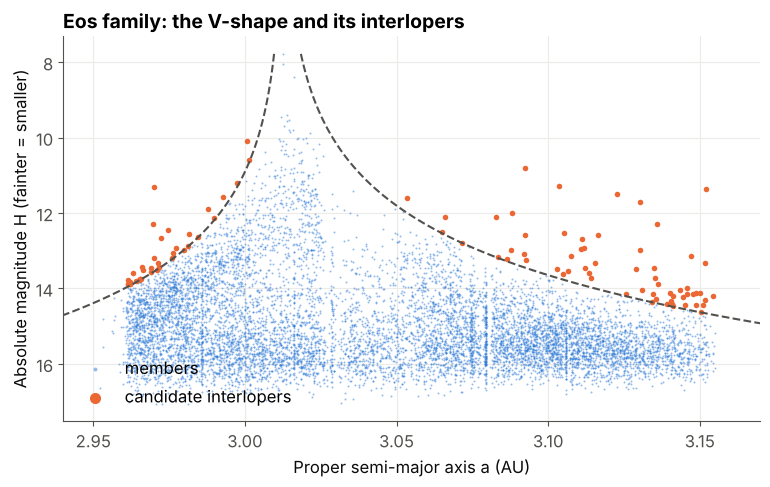

In [31]:
eos = df[df.fam_name == "221 Eos"].copy()
a_c = eos.loc[eos.H.idxmin(), "a"]                      # centre = largest member, (221) Eos
eos["C"] = (eos.a - a_c).abs() * 10 ** (-0.2 * eos.H)
eos["side"] = np.where(eos.a < a_c, "left", "right")
# the family is lopsided, so each wing of the V gets its own envelope: the 99th percentile of C on that side
c_max = eos.groupby("side").C.quantile(0.99)
eos["interloper"] = eos.C > eos.side.map(c_max)
print(f"Eos family: {len(eos):,} members, {eos.interloper.sum()} flagged as candidate interlopers")

fig, ax = plt.subplots(figsize=(9, 5))
ok = eos[~eos.interloper]; bad = eos[eos.interloper]
ax.scatter(ok.a, ok.H, s=2, color=BLUE, alpha=0.5, linewidths=0, rasterized=True, label="members")
ax.scatter(bad.a, bad.H, s=16, color=ORANGE, linewidths=0, label="candidate interlopers")
hh = np.linspace(eos.H.min(), eos.H.max(), 100)
ax.plot(a_c - c_max["left"] * 10 ** (0.2 * hh), hh, color=INK2, lw=1.5, ls="--")
ax.plot(a_c + c_max["right"] * 10 ** (0.2 * hh), hh, color=INK2, lw=1.5, ls="--")
ax.invert_yaxis(); ax.set_xlabel("Proper semi-major axis a (AU)"); ax.set_ylabel("Absolute magnitude H (fainter = smaller)")
ax.set_xlim(2.94, 3.17); ax.legend(loc="lower left", markerscale=2)
ax.set_title("Eos family: the V-shape and its interlopers", loc="left")
save(fig, "interlopers_eos"); plt.show()

## 12. Summary

In [32]:
d = evaluation.set_index(["method", "zone"]).ARI
print(f"Asteroids analysed          : {len(df):,}")
print(f"Reference families in final data: {df[df.fam_id >= 0].fam_id.nunique()}")
print(f"DBSCAN ARI (inner/middle/outer): " + " / ".join(f"{d['DBSCAN', z]:.2f}" for z in ZONES))
print(f"K-means ARI (inner/middle/outer): " + " / ".join(f"{d['K-means', z]:.2f}" for z in ZONES))
print(f"Large families recovered with Jaccard > 0.5: {(recovery.jaccard > 0.5).sum()} of {len(recovery)}")

Asteroids analysed          : 382,730


Reference families in final data: 98
DBSCAN ARI (inner/middle/outer): 0.64 / 0.61 / 0.65
K-means ARI (inner/middle/outer): 0.07 / 0.01 / 0.03
Large families recovered with Jaccard > 0.5: 10 of 14
